In [1]:
import sys

sys.path.append("../src")
from configs.load_config import load_config
from data_processing.load import load_dataset
from models.build import build_model
from training.train import train_torch, sample_numpyro
import matplotlib.pyplot as plt
from training.evaluate import evaluate_model, evaluate_numpyro
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import (
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_residuals,
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_first_layer_feature_posteriors,
    plot_bnn_weight_posteriors,
    plot_posterior_predictive_vs_likelihood,
    plot_stacked_hdi_intervals,
    plot_pit_histogram,
    extract_quantile_curves,
    evaluate_and_plot_qr_ensemble_medians,
    plot_posterior_predictive_family,
    plot_qr_hdi_prediction_ensemble,
)
import torch
import numpy as np
import numpyro
from data_processing.utils import (
    load_torch_model,
    load_checkpoint,
    save_scaler_params,
    approximate_qr_intervals,
)
import pandas as pd

In [2]:
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import plot_qr_hdi_prediction_ensemble

In [3]:
# model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
# file_name = "WindPowerQuantile_2025-12-21_10-21-23_forecast_gen_ELSPOT_NO1"

model_cfg = load_config("../configs/model/bnn_gen_model_forecast.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "model_mw_gamma_2026-02-04_10-02-43_nowcast_ELSPOT_NO1"  # model_mw_gamma_extended_2026-02-04_12-53-56_nowcast_ELSPOT_NO3"  # "model_mw_gamma_2026-01-16_03-18-21_nowcast_ELSPOT_NO3"  # "model_mw_gamma_2026-01-15_23-33-09_nowcast_ELSPOT_NO1"  # "model_mw_gamma_2026-01-15_20-24-15_nowcast_ELSPOT_NO1"  # "WindPowerQuantile_2026-01-14_10-30-39_nowcast_gen_ELSPOT_NO3"  # "WindPowerQuantile_2026-01-14_10-25-57_nowcast_gen_ELSPOT_NO1"
# file_name = "model_mw_gamma_2026-01-15_23-33-09_nowcast_ELSPOT_NO1"
# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast.yaml")
# file_name = "model_mw_gamma_2025-12-20_20-08-12_nowcast_ELSPOT_NO1"

In [4]:
data_cfg.dataset = "forecast"

In [5]:
data = load_dataset(data_cfg)

Loading forecast data for ELSPOT NO1, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
RangeIndex(start=0, stop=6874212, step=1)
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=6874212, step=1)
All parks operational from 2022-10-26 22:00:00
Before 2-day ahead filtering: 323718 rows
After 2-day ahead filtering: 120222 rows
Lead time range: 34.0h to 61.0h


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Maintenance hours in operational period: 8
      air_temperature_2m_member_0  air_temperature_2m_member_1  \
mean                    -0.069683                    -0.069915   
std                      0.988244                     0.988472   

      air_temperature_2m_member_2  air_temperature_2m_member_3  \
mean                    -0.070168                    -0.069792   
std                      0.989319                     0.988857   

      air_temperature_2m_member_4  air_temperature_2m_member_5  \
mean                    -0.070115                    -0.069524   
std                      0.987820                     0.988062   

      air_temperature_2m_member_6  air_temperature_2m_member_7  \
mean                    -0.069132                    -0.069842   
std                      0.988916                     0.989084   

      air_temperature_2m_member_8  air_temperature_2m_member_9  ...  \
mean                    -0.069364                    -0.070118  ...   
std                

In [6]:
save_scaler_params(
    scaler_params=data["scaler_params"],
    site_scaler_params=data["site_scaler_params"],
    bid_zone=data_cfg.bid_zone,
    split_time=pd.Timestamp("2025-01-01 00:00:00", tz="CET"),
    dataset=data_cfg.dataset,
    dir_path="../checkpoints",
)

Saved scaler parameters for ELSPOT NO1: ../checkpoints/scaler_params_ELSPOT_NO1_forecast.pkl


'../checkpoints/scaler_params_ELSPOT_NO1_forecast.pkl'

In [7]:
median_list = []
hdi_list = []
percentile_list = []
y_pred_list = []

for member in range(15):

    if model_cfg.backend == "torch":
        # Quantiles
        if model_cfg.params.quantiles is None:
            quantiles = torch.linspace(0, 1, 51)
        else:
            quantiles = torch.tensor(model_cfg.params.quantiles)

        model, checkpoint = load_torch_model(
            file_name=file_name,
        )

        metrics, y_pred = evaluate_model(
            model=model,
            data=data,
            quantiles=quantiles,
            model_cfg=checkpoint["model_cfg"],
            data_cfg=data_cfg,
        )

        hdis, _, _, _ = approximate_qr_intervals(
            Y_pred=y_pred,
            taus=quantiles,
            cred_mass=0.95,
        )

        # Extract curves, TODO: not 95% CI!!
        median, lower, upper = extract_quantile_curves(
            Y_pred_quantiles=y_pred,
            quantiles=quantiles,
            median_q=0.5,
            lower_q=0.02,
            upper_q=0.98,
        )

        percentiles = np.stack([lower, upper], axis=1)

    elif model_cfg.backend == "numpyro":

        checkpoint = load_checkpoint(file_name=file_name)
        model = build_model(checkpoint["model_cfg"], data)
        samples = checkpoint["samples"]
        metrics, y_pred, predictive, median, percentiles, hdis = evaluate_numpyro(
            model=model,
            samples=checkpoint["samples"],
            rng_key_predict=checkpoint["rng_key_predict"],
            data=data,
            model_cfg=checkpoint["model_cfg"],
            member=member,
        )

        median_list.append(median)
        hdi_list.append(hdis)
        percentile_list.append(percentiles)
        y_pred_list.append(y_pred)

    # print(metrics)

    if data["X_train"].shape != 4:
        # validate on nowcast, only one loop, otherwise validation on all ensemble members
        break


# assert checkpoint["model_cfg"] == model_cfg

Loading specified checkpoint: ../checkpoints/model_mw_gamma_2026-02-04_10-02-43_nowcast_ELSPOT_NO1.pkl
dict_keys(['Y', 'alpha', 'mu'])
RMSE train: 61.41999
CRPS train:  32.429920196526474


In [8]:
median_df = pd.DataFrame(
    np.column_stack(median_list),
    columns=[f"median_{i}" for i in range(len(median_list))],
)

hdi_dict = {}

for i, arr in enumerate(hdi_list):
    hdi_dict[f"hdi_lower_{i}"] = arr[0]
    hdi_dict[f"hdi_upper_{i}"] = arr[1]

hdi_df = pd.DataFrame(hdi_dict)

ensemble_results = pd.concat([median_df, hdi_df], axis=1)

median_cols = ensemble_results.filter(regex=r"^median_").columns
hdi_lower_cols = ensemble_results.filter(regex=r"^hdi_lower_").columns
hdi_upper_cols = ensemble_results.filter(regex=r"^hdi_upper_").columns

ensemble_results["mean_median"] = ensemble_results[median_cols].mean(axis=1)
ensemble_results["std_median"] = ensemble_results[median_cols].std(axis=1)
ensemble_results["mean_hdi_lower"] = ensemble_results[hdi_lower_cols].mean(axis=1)
ensemble_results["std_hdi_lower"] = ensemble_results[hdi_lower_cols].std(axis=1)
ensemble_results["mean_hdi_upper"] = ensemble_results[hdi_upper_cols].mean(axis=1)
ensemble_results["std_hdi_upper"] = ensemble_results[hdi_upper_cols].std(axis=1)

In [9]:
samples = checkpoint["samples"]

In [10]:
# import numpy as np

# for k, v in samples.items():
#     v = np.asarray(v)
#     print(
#         f"{k:20s} shape={v.shape} finite={np.isfinite(v).all()} "
#         f"min={np.nanmin(v):.3g} max={np.nanmax(v):.3g}"
#     )

In [11]:
# import numpy as np
# import arviz as az

# posterior = {k: np.asarray(v)[None, ...] for k, v in samples.items()}  # (1, 100, ...)

# idata = az.from_dict(posterior=posterior)
# az.plot_trace(idata, var_names=["b1", "b2", "b3mu", "b3k"])

In [12]:
# import matplotlib.pyplot as plt

# i = 0
# plt.plot(samples["mu"][:, i])
# plt.title(f"Trace mu[{i}]")
# plt.show()

### Plots


In [13]:
if model_cfg.backend == "numpyro":
    X_test = data["X_test"]
    if len(X_test.shape) == 4:
        X_test = X_test[:, :, 0]
    graph = numpyro.render_model(
        model,
        model_args=(X_test,),
    )
    graph

In [14]:
try:
    graph
except:
    pass

In [15]:
import torch
import numpy as np
from numpyro.infer import Predictive
from data_processing.preprocess import (
    to_tensor,
)
import arviz as az
import pandas as pd
from jax import random


from data_processing.utils import (
    load_checkpoint,
    load_torch_model,
    QuantileDistribution,
)
from models.model import model_mw_gamma, model_cf_logitnormal, model_cf_beta
import torch
import re


def evaluate_numpyro_on_train_set(model, samples, rng_key_predict, data, model_cfg):

    X_test = data["X_train"]
    Y = data["Y_train_gen"] if model_cfg.params.target == "gen" else data["Y_test_cf"]

    # Handle forecast vs nowcast
    if model_cfg.name in ["model_mw_gamma", "model_cf_beta"] and X_test.ndim == 4:
        X_test = X_test[:, :, 0]  # first ensemble member

    predictive = Predictive(model, samples)(rng_key_predict, X_test)

    # Handle CF prediction, transform it back to generation prediction
    y_pred = (
        predictive["Y"]
        if model_cfg.params.target == "gen"
        else predictive["Y"] * data["Y_train_aval"]
    )
    y_pred_median = np.percentile(y_pred, 50, axis=0)
    percentiles = np.percentile(y_pred, [2.5, 97.5], axis=0)
    hdis = az.hdi(np.expand_dims(y_pred, axis=0), hdi_prob=0.95).T

    metrics = {}

    metrics["rmse_median"] = np.sqrt(np.mean((y_pred_median - Y) ** 2))
    metrics["coverage_025_975"] = ((Y >= percentiles[0]) & (Y <= percentiles[1])).mean()
    metrics["coverage_0_50"] = (Y <= y_pred_median).mean()

    # Percentiles shape: [t_test, 2]
    return metrics, y_pred, predictive, y_pred_median, percentiles.T, hdis


(
    metrics_train,
    y_pred_train,
    predictive_train,
    median_train,
    percentiles_train,
    hdis_train,
) = evaluate_numpyro_on_train_set(
    model, checkpoint["samples"], checkpoint["rng_key_predict"], data, model_cfg
)

In [16]:
data["Y_test_gen"].max()

np.float32(378.96204)

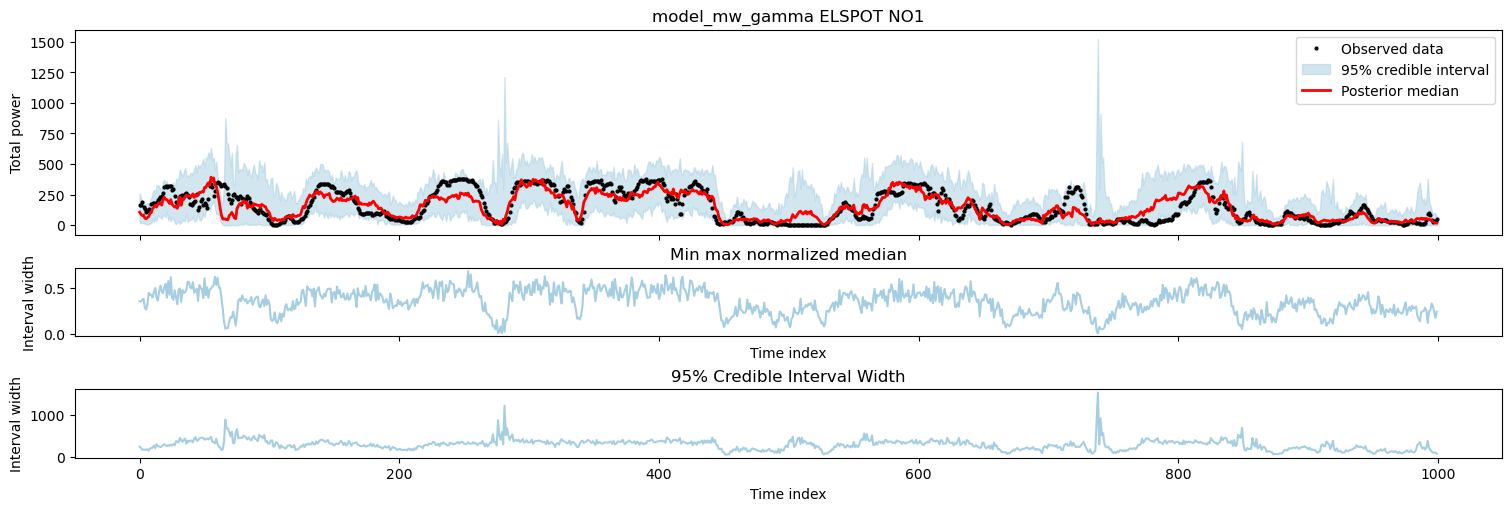

In [17]:
# Plot

fig, axes = plot_qr_hdi_prediction(
    Y_true=data["Y_test_gen"],
    conf_interval=hdi_list[0].T,
    medians=median_list[0],
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone}",
)
plt.show()

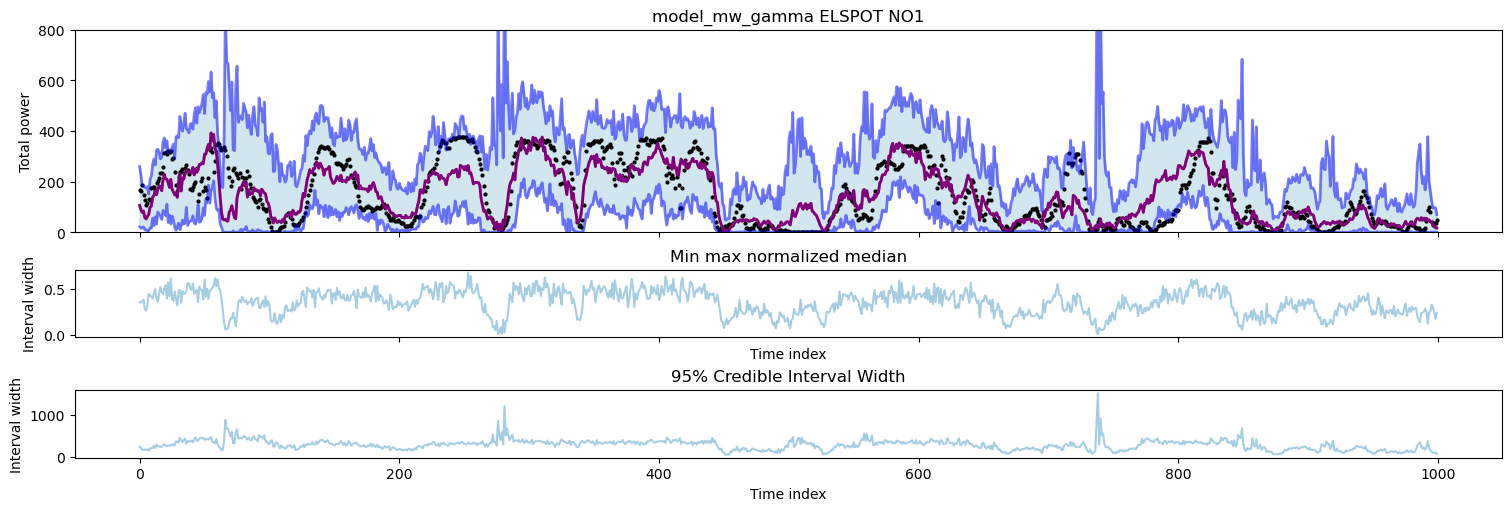

In [18]:
fig, axes = plot_qr_hdi_prediction_ensemble(
    Y_true=data["Y_test_gen"],
    ensemble_results=ensemble_results,
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone}",
)
plt.show()

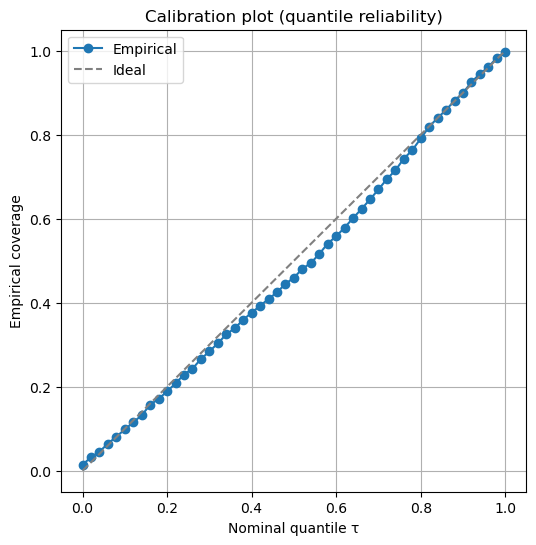

In [19]:
# y_pred: (S, N)

quantiles = torch.linspace(0, 1, 51)
emp_cov = plot_quantile_calibration(
    Y_pred_quantiles=(
        np.quantile(y_pred_list[0], quantiles, axis=0).T
        if model_cfg.backend == "numpyro"
        else y_pred
    ),
    Y_true=(
        data["Y_test_gen"] if model_cfg.params.target == "gen" else data["Y_test_cf"]
    ),
    quantiles=quantiles,
)

skew: 0.09820975


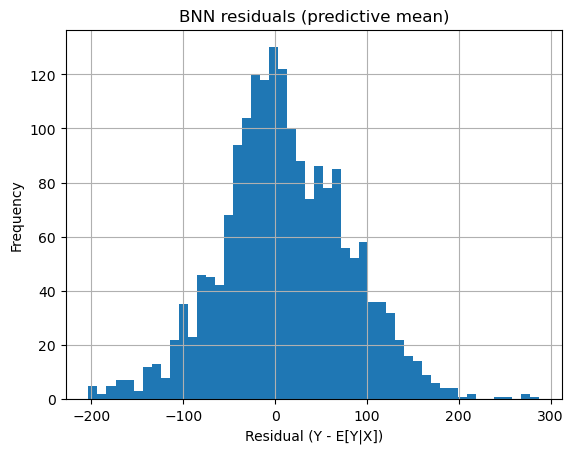

array([ 62.284653,  73.78912 , 108.62665 , ..., 143.27206 , 117.76651 ,
       118.665405], shape=(1895,), dtype=float32)

In [20]:
plot_residuals(
    median_list[0],
    data["Y_test_gen"],
)

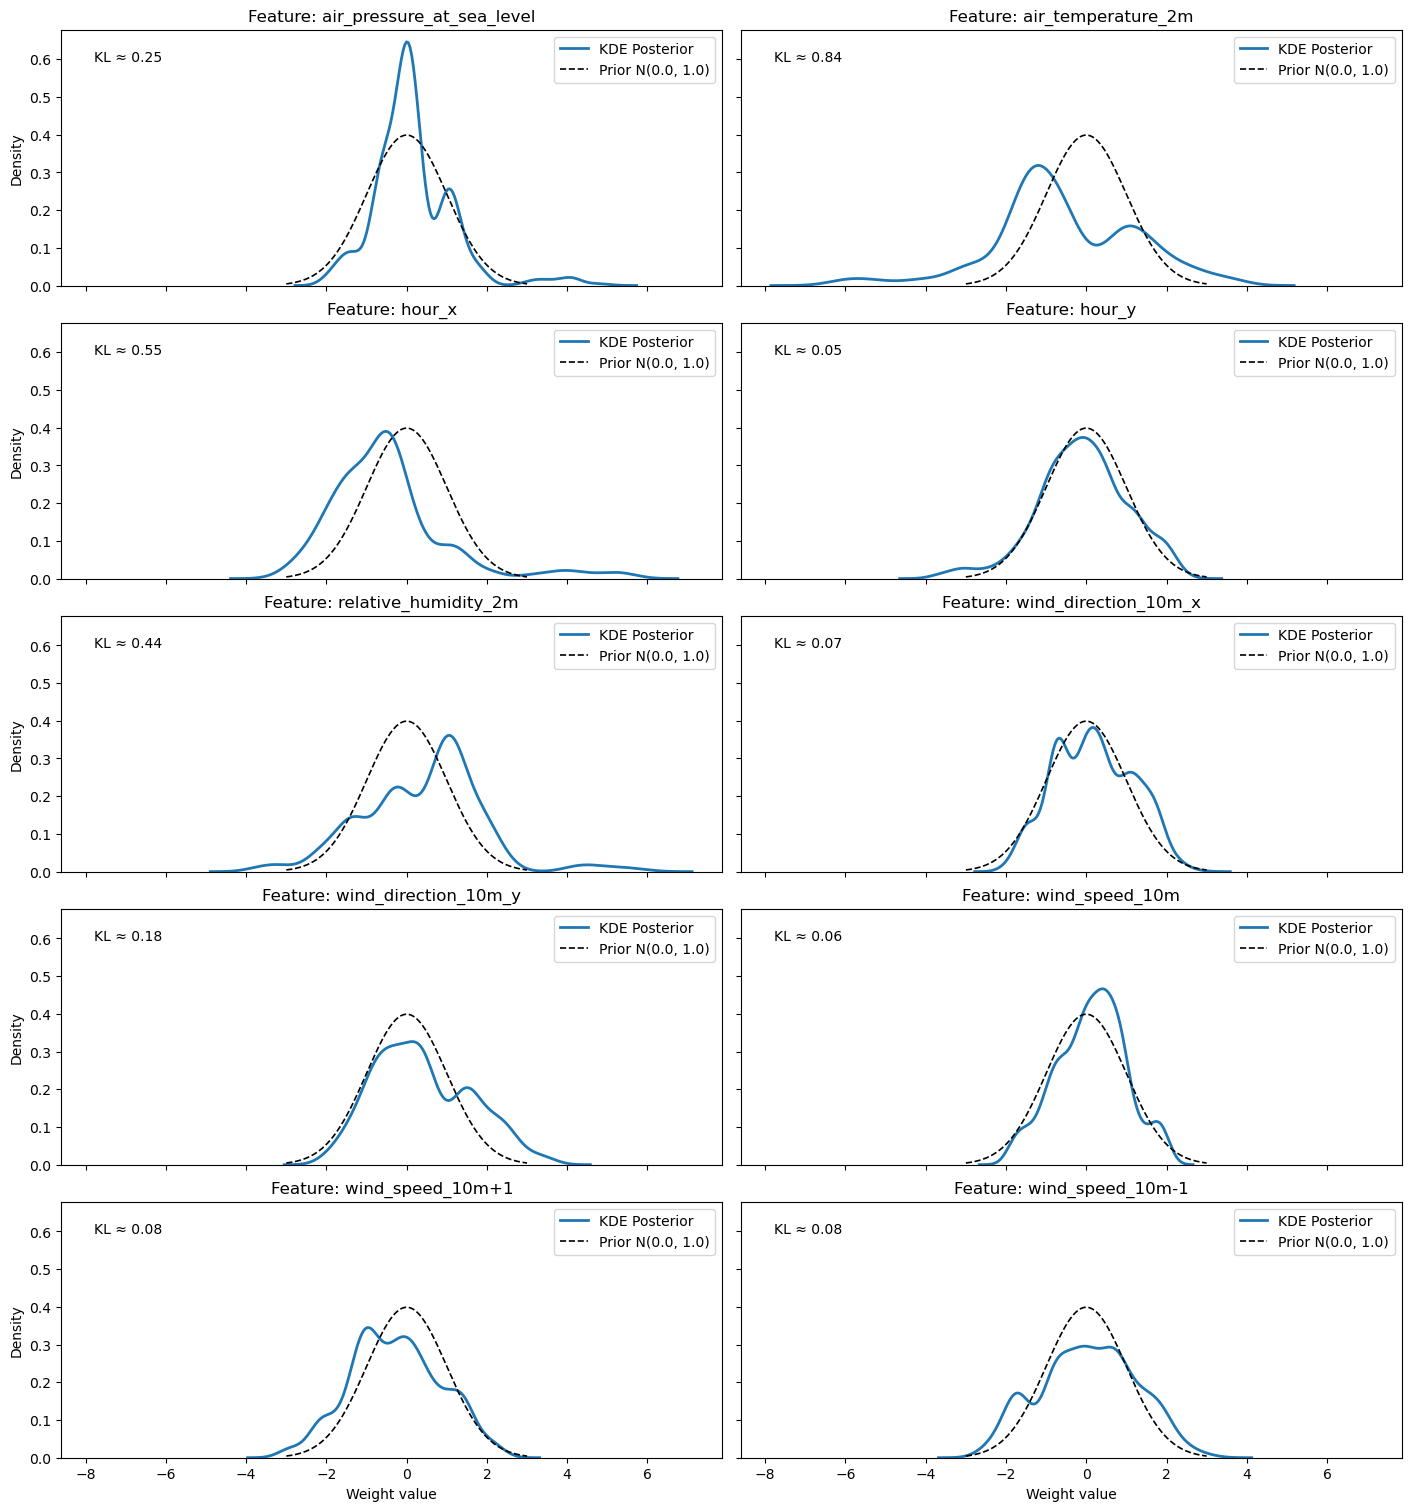

In [21]:
if model_cfg.backend == "numpyro":
    plot_first_layer_feature_posteriors(checkpoint["samples"], data)

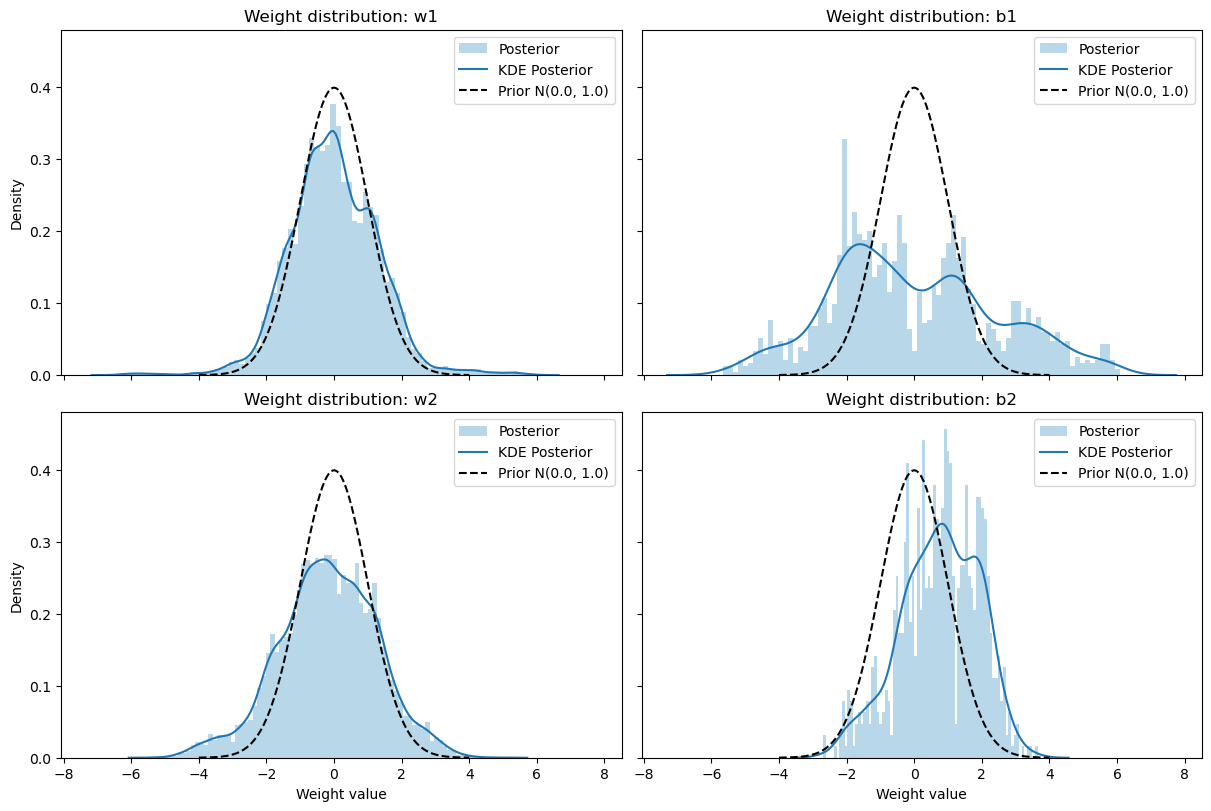

In [22]:
if model_cfg.backend == "numpyro":
    plot_bnn_weight_posteriors(checkpoint["samples"])

In [23]:
predictive

{'Y': Array([[ 14.678022,  89.97453 ,  92.66183 , ...,  54.66657 ,  14.399672,
          57.729176],
        [222.3331  , 135.37866 , 100.99612 , ...,  63.45244 , 107.0617  ,
          55.198395],
        [ 32.228554, 166.81197 , 230.23285 , ...,  69.15737 ,  56.043297,
          43.605556],
        ...,
        [146.42805 ,  78.14343 ,  67.8907  , ..., 188.91179 , 151.42546 ,
         129.48842 ],
        [ 91.16332 ,  59.67214 , 100.10774 , ..., 258.06006 , 243.45856 ,
         146.48834 ],
        [ 87.3783  ,  55.168587,  79.996185, ..., 216.01492 , 246.85982 ,
         205.40465 ]], dtype=float32),
 'alpha': Array([[ 1.409586 ,  2.0508971,  1.6371609, ...,  1.8216275,  1.893858 ,
          1.873194 ],
        [ 1.2468634,  1.8913232,  1.5118945, ...,  2.0840433,  2.1336966,
          2.1036177],
        [ 1.2545565,  1.896144 ,  1.6201614, ...,  2.0274174,  2.0765488,
          2.0383344],
        ...,
        [ 5.50758  ,  4.4536524,  5.1771502, ...,  7.89686  ,  9.576416 ,
     

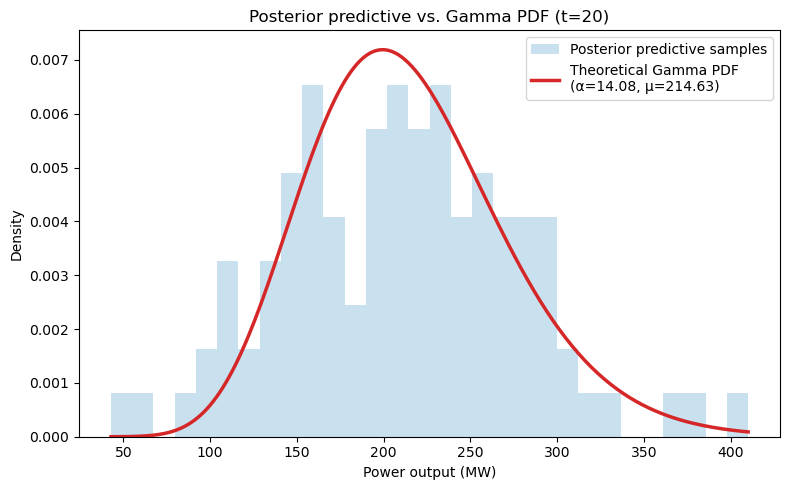

In [24]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_vs_likelihood(
        predictive=predictive,
        model_name=model_cfg.name,
        t=20,
    )

Y not none
319.0532531738281


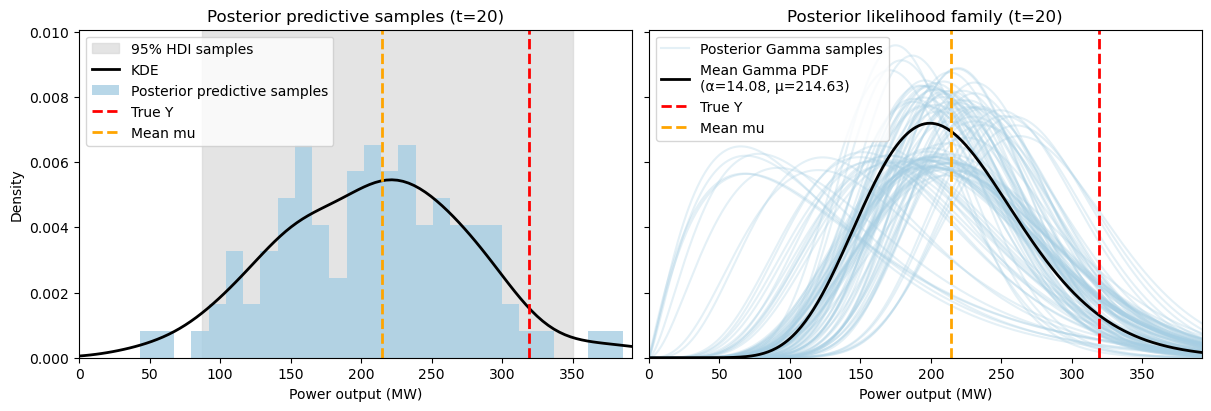

In [25]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_family(predictive, model_cfg, data, t=20, hdi=percentiles)

In [26]:
if model_cfg.backend == "torch":
    plt.figure(figsize=(8, 5))
    plt.plot(checkpoint["losses"], label="Training Loss")
    plt.xlabel("Step")
    plt.ylabel("MSE Loss")
    plt.title("Training Loss Over Time")
    plt.legend()
    plt.grid(True)
    plt.show()

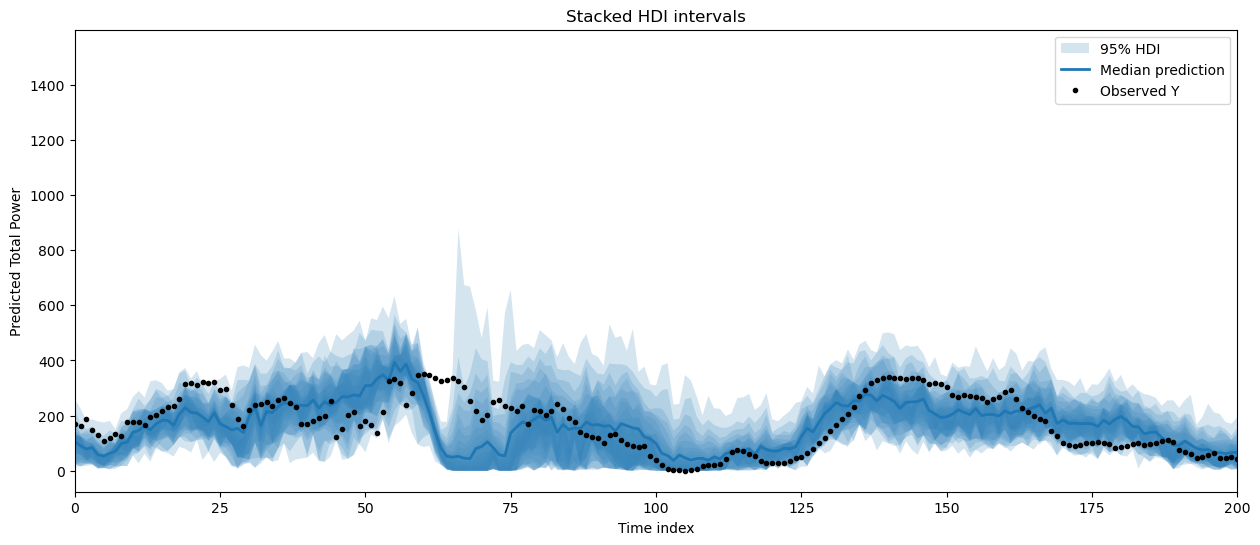

In [27]:
if model_cfg.backend == "numpyro":
    plot_stacked_hdi_intervals(
        preds=y_pred_list[0],
        Y_true=data["Y_test_gen"],
        n_plot=1000,
    )

PIT mean: 0.5162 (should be ~0.5 if calibrated)


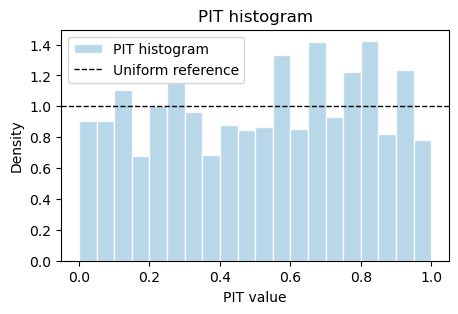

In [28]:
if model_cfg.backend == "numpyro":
    pits = plot_pit_histogram(
        preds=y_pred_list[0],
        Y_true=data["Y_test_gen"],
    )

In [29]:
if model_cfg.backend == "torch" and len(data["X_train"].shape) == 4:
    evaluate_and_plot_qr_ensemble_medians(
        model=model,
        data=data,
        quantiles=quantiles,
        n_members=15,
        n_plot=1000,
    )